# **Análisis Comparativo de Modelos CNN para el Reconocimiento de Lesiones Mamarias en Ecografías**

**Curso:** Sistemas Inteligentes y Machine Learning — Universidad Privada del Norte
**Docente:** Marcelino Torres Villanueva
**Dataset:** BUSI — Breast Ultrasound Images (Al-Dhabyani et al., 2020)

El experimento compara un **Modelo A** (CNN entrenada desde cero) con un **Modelo B** (CNN optimizada con transferencia de aprendizaje mediante EfficientNetB0 preentrenada en ImageNet). Antes de la partición, el dataset se depura de imágenes duplicadas por contenido. Los resultados se guardan en `resultados_proyecto_v2`.

Este notebook contiene el experimento completo del proyecto, organizado según las fases de CRISP-DM:

| Fase | Secciones del notebook |
|---|---|
| Comprensión de los datos | 1 – 4 |
| Preparación de los datos | 5 – 6, 8 |
| Modelado | 7, 9 – 12 |
| Evaluación | 13 – 18 |
| Despliegue (prototipo) | 19 – 20 |

**Antes de ejecutar:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)`. Luego `Entorno de ejecución → Ejecutar todas`.

# **0. Verificar que la GPU T4 está activa (ejecutar primero)**

1. Ejecute la celda de abajo con el botón ▶.
2. Si aparece una tabla que dice **Tesla T4**, todo está bien: vaya a `Entorno de ejecución → Ejecutar todas`.
3. Si aparece un error (*NVIDIA-SMI has failed* o *command not found*), vaya a `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU → Guardar` y vuelva a ejecutar esta celda.

In [1]:
!nvidia-smi

Thu Oct 29 06:50:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# **1. Configuración del entorno**

Se importan las librerías, se fija la semilla aleatoria (reproducibilidad) y se verifica que la GPU esté activa.

In [2]:
import os
import time
import random
import platform

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
import keras

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    RandomFlip,
    RandomRotation,
    RandomZoom
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Semilla global para que los resultados sean reproducibles
SEMILLA = 42
os.environ["PYTHONHASHSEED"] = str(SEMILLA)
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("scikit-learn:", sklearn.__version__)
print("OpenCV:", cv2.__version__)

Python: 3.13.16
TensorFlow: 2.21.0
Keras: 3.13.2
scikit-learn: 1.6.1
OpenCV: 5.0.0


In [3]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU disponible:", gpus)
else:
    print("ADVERTENCIA: no se detectó GPU. Cambie el entorno de ejecución a GPU.")

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# **2. Acceso a los datos (Google Drive)**

El dataset BUSI está almacenado en Google Drive en la carpeta `MyDrive/DataSetKaggle/Dataset_BUSI_with_GT`, con tres subcarpetas: `normal`, `benign` y `malignant`.

También se crea una carpeta `resultados_proyecto_v2` en Drive para guardar modelos, figuras y tablas.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
ruta_dataset = "/content/drive/MyDrive/DataSetKaggle/Dataset_BUSI_with_GT"

# Carpeta donde se guardarán modelos, figuras y tablas de resultados
ruta_resultados = "/content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2"
os.makedirs(ruta_resultados, exist_ok=True)

print("Ruta del dataset:", ruta_dataset)
print("Ruta de resultados:", ruta_resultados)

if os.path.exists(ruta_dataset):
    print("\nDataset encontrado correctamente.")
else:
    print("\nERROR: No se encontró el dataset. Revise la ruta en Drive.")

Ruta del dataset: /content/drive/MyDrive/DataSetKaggle/Dataset_BUSI_with_GT
Ruta de resultados: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2

Dataset encontrado correctamente.


In [6]:
print("Contenido principal del dataset:\n")

for elemento in sorted(os.listdir(ruta_dataset)):
    print(elemento)

Contenido principal del dataset:

benign
malignant
normal


In [7]:
# Función auxiliar para guardar cada figura en Drive (para el informe)
def guardar_figura(nombre):
    ruta = os.path.join(ruta_resultados, nombre)
    plt.savefig(ruta, dpi=200, bbox_inches="tight")
    print("Figura guardada en:", ruta)

# **3. Comprensión de los datos**

## 3.1 Inventario de imágenes originales y máscaras

Cada clase contiene imágenes originales y máscaras *Ground Truth* (archivos con `_mask`). Las máscaras sirven para segmentación, por lo que **se excluyen** de la clasificación.

In [8]:
print("Cantidad de imágenes originales y máscaras por clase:\n")

total_originales = 0
total_mascaras = 0

for carpeta in sorted(os.listdir(ruta_dataset)):

    ruta_carpeta = os.path.join(ruta_dataset, carpeta)

    if os.path.isdir(ruta_carpeta):

        archivos = os.listdir(ruta_carpeta)

        # Imágenes originales
        originales = [
            archivo for archivo in archivos
            if archivo.lower().endswith(".png")
            and "_mask" not in archivo.lower()
        ]

        # Máscaras Ground Truth
        mascaras = [
            archivo for archivo in archivos
            if archivo.lower().endswith(".png")
            and "_mask" in archivo.lower()
        ]

        print(f"{carpeta}")
        print(f"  Imágenes originales: {len(originales)}")
        print(f"  Máscaras: {len(mascaras)}")
        print()

        total_originales += len(originales)
        total_mascaras += len(mascaras)

print("Total de imágenes originales:", total_originales)
print("Total de máscaras:", total_mascaras)
print("Total de archivos PNG:", total_originales + total_mascaras)

Cantidad de imágenes originales y máscaras por clase:

benign
  Imágenes originales: 437
  Máscaras: 454

malignant
  Imágenes originales: 210
  Máscaras: 211

normal
  Imágenes originales: 133
  Máscaras: 133

Total de imágenes originales: 780
Total de máscaras: 798
Total de archivos PNG: 1578


## 3.2 Construcción del DataFrame de imágenes

Se registra cada imagen original con su nombre, su clase diagnóstica y su ruta. Este DataFrame es el **instrumento de registro** de los datos.

In [9]:
datos = []

for clase in sorted(os.listdir(ruta_dataset)):

    ruta_clase = os.path.join(ruta_dataset, clase)

    if os.path.isdir(ruta_clase):

        for archivo in sorted(os.listdir(ruta_clase)):

            # Solo imágenes originales (se excluyen las máscaras)
            if archivo.lower().endswith(".png") and "_mask" not in archivo.lower():

                datos.append({
                    "nombre_archivo": archivo,
                    "clase_diagnostico": clase,
                    "ruta_imagen": os.path.join(ruta_clase, archivo)
                })

df_imagenes = pd.DataFrame(datos)

print("Cantidad de observaciones:", len(df_imagenes))
df_imagenes.head()

Cantidad de observaciones: 780


,nombre_archivo,clase_diagnostico,ruta_imagen
0,benign (1).png,benign,/content/drive/MyDrive/DataSetKaggle/Dataset_B...
1,benign (10).png,benign,/content/drive/MyDrive/DataSetKaggle/Dataset_B...
2,benign (100).png,benign,/content/drive/MyDrive/DataSetKaggle/Dataset_B...
3,benign (101).png,benign,/content/drive/MyDrive/DataSetKaggle/Dataset_B...
4,benign (102).png,benign,/content/drive/MyDrive/DataSetKaggle/Dataset_B...


## 3.3 Distribución de las clases

In [10]:
distribucion = df_imagenes["clase_diagnostico"].value_counts()
porcentajes = df_imagenes["clase_diagnostico"].value_counts(normalize=True) * 100

tabla_distribucion = pd.DataFrame({
    "cantidad": distribucion,
    "porcentaje (%)": porcentajes.round(2)
})

tabla_distribucion

,cantidad,porcentaje (%)
clase_diagnostico,,
benign,437,56.03
malignant,210,26.92
normal,133,17.05


Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_distribucion_clases.png


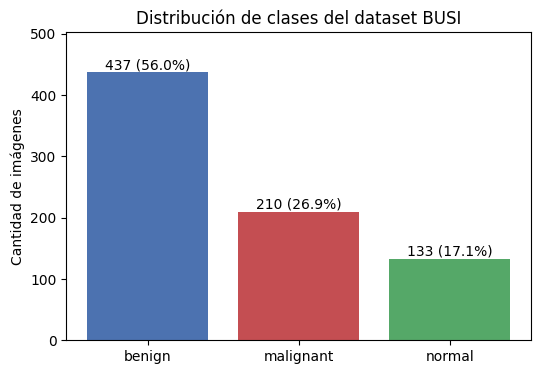

In [11]:
plt.figure(figsize=(6, 4))

colores = {"benign": "#4C72B0", "malignant": "#C44E52", "normal": "#55A868"}

barras = plt.bar(
    distribucion.index,
    distribucion.values,
    color=[colores[c] for c in distribucion.index]
)

for barra, valor in zip(barras, distribucion.values):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 5,
        f"{valor} ({valor / len(df_imagenes) * 100:.1f}%)",
        ha="center"
    )

plt.title("Distribución de clases del dataset BUSI")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, distribucion.max() * 1.15)
guardar_figura("fig_distribucion_clases.png")
plt.show()

## 3.4 Ejemplos de ecografías por clase

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_ejemplos_por_clase.png


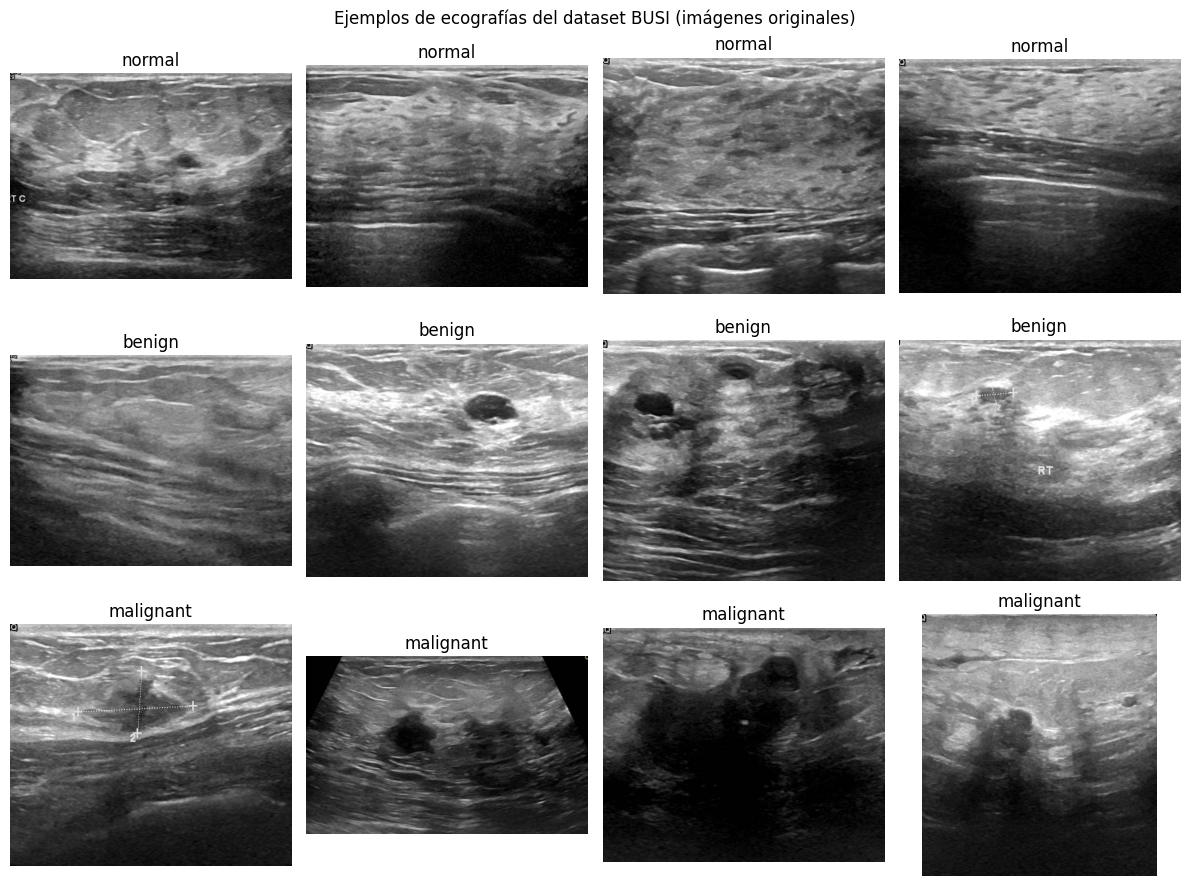

In [12]:
CLASES_ORDEN = ["normal", "benign", "malignant"]

fig, ejes = plt.subplots(3, 4, figsize=(12, 9))

for fila, clase in enumerate(CLASES_ORDEN):

    muestra = df_imagenes[df_imagenes["clase_diagnostico"] == clase].sample(4, random_state=SEMILLA)

    for columna, ruta in enumerate(muestra["ruta_imagen"]):

        imagen = cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)

        ejes[fila, columna].imshow(imagen)
        ejes[fila, columna].set_title(clase)
        ejes[fila, columna].axis("off")

plt.suptitle("Ejemplos de ecografías del dataset BUSI (imágenes originales)")
plt.tight_layout()
guardar_figura("fig_ejemplos_por_clase.png")
plt.show()

# **4. Calidad de los datos**

## 4.1 Verificar que las imágenes puedan abrirse

Equivale al tratamiento de valores nulos: una imagen que no se puede leer sería un dato faltante.

In [13]:
imagenes_invalidas = []
dimensiones = []

for ruta in df_imagenes["ruta_imagen"]:

    imagen = cv2.imread(ruta)

    if imagen is None:
        imagenes_invalidas.append(ruta)
    else:
        alto, ancho = imagen.shape[:2]
        dimensiones.append((ancho, alto))

print("Imágenes que no pudieron cargarse:", len(imagenes_invalidas))

Imágenes que no pudieron cargarse: 0


## 4.2 Comprobar las dimensiones reales

Las ecografías tienen tamaños distintos, por eso es obligatorio redimensionarlas a un tamaño fijo.

In [14]:
df_dimensiones = pd.DataFrame(dimensiones, columns=["ancho", "alto"])

print("Primeras dimensiones encontradas:")
print(dimensiones[:10])

print("\nCantidad de dimensiones diferentes:", len(set(dimensiones)))

print("\nResumen estadístico de las dimensiones (píxeles):")
df_dimensiones.describe().round(1)

Primeras dimensiones encontradas:
[(562, 471), (683, 585), (323, 473), (563, 473), (634, 610), (766, 585), (777, 578), (882, 581), (808, 716), (759, 616)]

Cantidad de dimensiones diferentes: 639

Resumen estadístico de las dimensiones (píxeles):


,ancho,alto
count,780.0,780.0
mean,615.7,501.5
std,122.1,76.7
min,190.0,310.0
25%,554.0,465.0
50%,564.0,474.0
75%,713.5,574.0
max,1048.0,719.0


## 4.3 Detección de imágenes duplicadas por contenido

La verificación por nombre de archivo no detecta una misma ecografía guardada con nombres distintos. Si una copia queda en Training y otra en Test, el modelo "vería" imágenes de prueba durante el entrenamiento (**data leakage**).

Para evitarlo, cada imagen se resume en una **huella digital de contenido** (*difference hash* de 256 bits calculado sobre la imagen en escala de grises reducida a 17 × 16 píxeles). Se comparan todas las parejas de imágenes: si sus huellas difieren en **10 bits o menos** (distancia de Hamming ≤ 10 de 256), se consideran la misma ecografía aunque tengan nombre, tamaño o compresión diferentes. También se calcula una huella exacta (MD5 de los píxeles) para contar las copias idénticas.

In [15]:
import hashlib

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

UMBRAL_HAMMING = 10   # bits distintos permitidos (de 256) para considerar dos imágenes duplicadas


def huella_perceptual(imagen_gris, tam=16):
    # Reducir a (tam + 1) x tam y comparar cada píxel con su vecino derecho
    reducida = cv2.resize(imagen_gris, (tam + 1, tam), interpolation=cv2.INTER_AREA)
    return (reducida[:, 1:] > reducida[:, :-1]).flatten()


def huella_exacta(imagen_gris):
    contenido = str(imagen_gris.shape).encode() + imagen_gris.tobytes()
    return hashlib.md5(contenido).hexdigest()


huellas_perceptuales = []
huellas_exactas = []

for ruta in df_imagenes["ruta_imagen"]:
    gris = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    huellas_perceptuales.append(huella_perceptual(gris))
    huellas_exactas.append(huella_exacta(gris))

df_imagenes["huella_exacta"] = huellas_exactas

# Distancia de Hamming entre todas las parejas de huellas (matriz n x n)
bits = np.array(huellas_perceptuales, dtype=np.uint8)
distancias = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)

# Agrupar las imágenes conectadas por una distancia <= umbral
conexiones = csr_matrix((distancias <= UMBRAL_HAMMING) & ~np.eye(len(bits), dtype=bool))
_, etiquetas_grupo = connected_components(conexiones, directed=False)
df_imagenes["grupo_duplicado"] = etiquetas_grupo

tamanos = df_imagenes["grupo_duplicado"].map(df_imagenes["grupo_duplicado"].value_counts())
grupos = df_imagenes[tamanos > 1]

print("Imágenes analizadas:", len(df_imagenes))
print("Copias idénticas píxel a píxel:", int(df_imagenes["huella_exacta"].duplicated().sum()))
print("Grupos de imágenes duplicadas por contenido:", grupos["grupo_duplicado"].nunique())
print("Imágenes involucradas en esos grupos:", len(grupos))

if len(grupos) > 0:
    display(grupos.sort_values(["grupo_duplicado", "nombre_archivo"])[["grupo_duplicado", "nombre_archivo", "clase_diagnostico"]])

Imágenes analizadas: 780
Copias idénticas píxel a píxel: 1
Grupos de imágenes duplicadas por contenido: 27
Imágenes involucradas en esos grupos: 59


,grupo_duplicado,nombre_archivo,clase_diagnostico
1,1,benign (10).png,benign
253,1,benign (327).png,benign
7,7,benign (105).png,benign
63,7,benign (156).png,benign
34,34,benign (13).png,benign
257,34,benign (330).png,benign
36,36,benign (131).png,benign
594,36,malignant (51).png,malignant
44,44,benign (139).png,benign
64,44,benign (157).png,benign


### Revisión visual de los duplicados encontrados

Se muestran hasta 6 grupos para confirmar visualmente que se trata de la misma ecografía.

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_duplicados.png


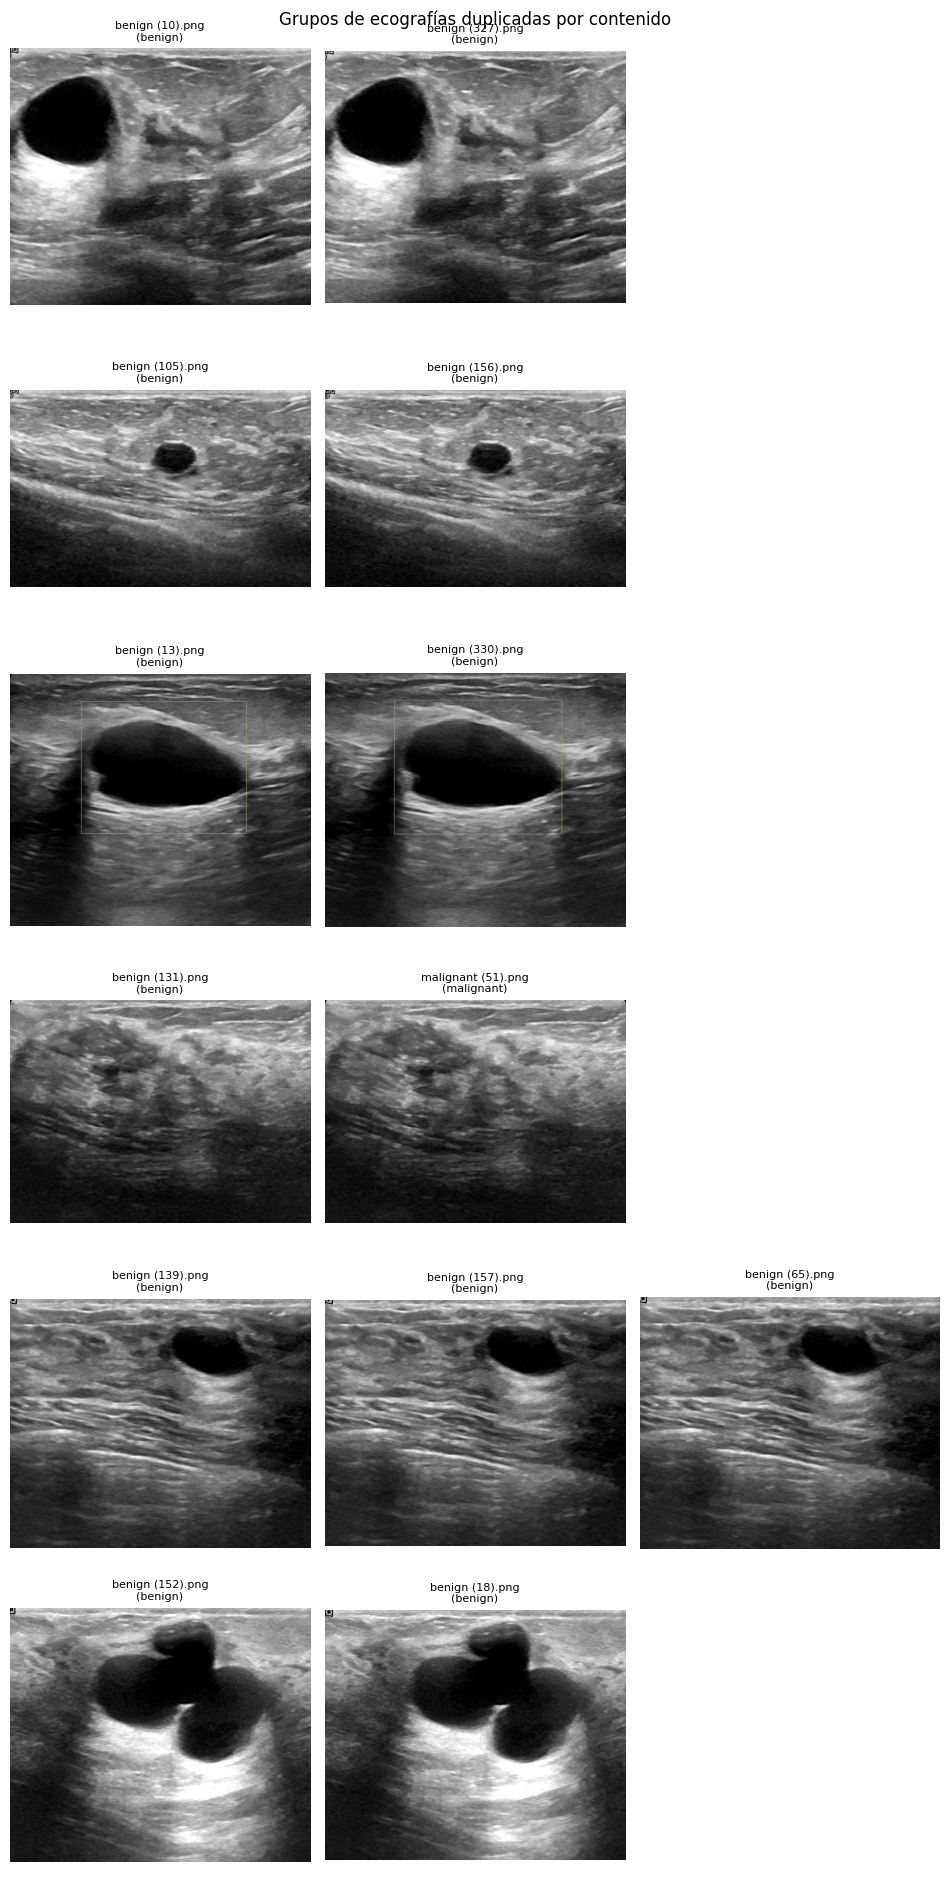

In [16]:
lista_grupos = [g for _, g in grupos.groupby("grupo_duplicado")][:6]

if lista_grupos:

    max_por_grupo = max(len(g) for g in lista_grupos)
    fig, ejes = plt.subplots(len(lista_grupos), max_por_grupo,
                             figsize=(3.2 * max_por_grupo, 3.2 * len(lista_grupos)), squeeze=False)

    for fila, grupo in enumerate(lista_grupos):
        for columna in range(max_por_grupo):
            eje = ejes[fila, columna]
            eje.axis("off")
            if columna < len(grupo):
                registro = grupo.iloc[columna]
                eje.imshow(cv2.cvtColor(cv2.imread(registro["ruta_imagen"]), cv2.COLOR_BGR2RGB))
                eje.set_title(f"{registro['nombre_archivo']}\n({registro['clase_diagnostico']})", fontsize=8)

    plt.suptitle("Grupos de ecografías duplicadas por contenido")
    plt.tight_layout()
    guardar_figura("fig_duplicados.png")
    plt.show()

else:
    print("No se encontraron imágenes duplicadas por contenido.")

## 4.4 Depuración del dataset

Regla aplicada a cada grupo de duplicados:

- **Misma clase en todas las copias:** se conserva una sola imagen (la primera en orden alfabético) y se eliminan las demás.
- **Clases distintas entre copias (etiqueta contradictoria):** se eliminan **todas** las copias, porque no es posible saber cuál etiqueta es la correcta.

La depuración se realiza **antes** de la partición, para que ninguna ecografía quede repetida entre Training, Validation y Test.

In [17]:
registro_depuracion = []
indices_a_eliminar = []

for _, grupo in df_imagenes.groupby("grupo_duplicado"):

    if len(grupo) < 2:
        continue

    grupo = grupo.sort_values("nombre_archivo")
    clases = grupo["clase_diagnostico"].unique()

    if len(clases) == 1:
        eliminar = grupo.index[1:]
        motivo = "Duplicado de la misma clase (se conserva una copia)"
    else:
        eliminar = grupo.index
        motivo = "Etiquetas contradictorias (se eliminan todas las copias)"

    indices_a_eliminar.extend(eliminar)

    for indice in eliminar:
        registro_depuracion.append({
            "nombre_archivo": df_imagenes.loc[indice, "nombre_archivo"],
            "clase_diagnostico": df_imagenes.loc[indice, "clase_diagnostico"],
            "motivo": motivo
        })

df_depuracion = pd.DataFrame(registro_depuracion, columns=["nombre_archivo", "clase_diagnostico", "motivo"])

df_original = df_imagenes.copy()
df_imagenes = df_imagenes.drop(index=indices_a_eliminar).reset_index(drop=True)

print("Imágenes antes de la depuración:", len(df_original))
print("Imágenes eliminadas:", len(df_depuracion))
print("Imágenes después de la depuración:", len(df_imagenes))

tabla_depuracion = pd.DataFrame({
    "Antes": df_original["clase_diagnostico"].value_counts(),
    "Eliminadas": df_depuracion["clase_diagnostico"].value_counts() if len(df_depuracion) else 0,
    "Después": df_imagenes["clase_diagnostico"].value_counts()
}).fillna(0).astype(int)

tabla_depuracion.loc["TOTAL"] = tabla_depuracion.sum()

print("\nImágenes por clase antes y después de la depuración:")
display(tabla_depuracion)

if len(df_depuracion):
    print("\nMotivos de eliminación:")
    print(df_depuracion["motivo"].value_counts())

Imágenes antes de la depuración: 780
Imágenes eliminadas: 34
Imágenes después de la depuración: 746

Imágenes por clase antes y después de la depuración:


,Antes,Eliminadas,Después
clase_diagnostico,,,
benign,437,24,413
malignant,210,3,207
normal,133,7,126
TOTAL,780,34,746



Motivos de eliminación:
motivo
Duplicado de la misma clase (se conserva una copia)         30
Etiquetas contradictorias (se eliminan todas las copias)     4
Name: count, dtype: int64


# **5. Preprocesamiento**

## 5.1 Constantes del pipeline

In [18]:
# Tamaño estándar para las imágenes
IMG_ALTO = 224
IMG_ANCHO = 224

# Número de clases del problema
NUM_CLASES = 3

# Nombres de las clases (el índice de cada clase es su posición en la lista)
CLASES = ["benign", "malignant", "normal"]
CLASE_A_INDICE = {clase: indice for indice, clase in enumerate(CLASES)}

# Hiperparámetros generales
BATCH_SIZE = 32

print("Tamaño de entrada:", (IMG_ALTO, IMG_ANCHO))
print("Número de clases:", NUM_CLASES)
print("Clases:", CLASE_A_INDICE)

Tamaño de entrada: (224, 224)
Número de clases: 3
Clases: {'benign': 0, 'malignant': 1, 'normal': 2}


## 5.2 Codificación de la etiqueta

Cada clase se convierte en un número entero (0, 1, 2). Más adelante se convierte a formato *one-hot* para la función de pérdida `categorical_crossentropy`.

In [19]:
df_imagenes["etiqueta"] = df_imagenes["clase_diagnostico"].map(CLASE_A_INDICE)

df_imagenes[["nombre_archivo", "clase_diagnostico", "etiqueta"]].sample(5, random_state=SEMILLA)

,nombre_archivo,clase_diagnostico,etiqueta
208,benign (30).png,benign,0
259,benign (350).png,benign,0
97,benign (190).png,benign,0
148,benign (236).png,benign,0
395,benign (82).png,benign,0


## 5.3 Función de preprocesamiento

Lee la imagen, la decodifica con 3 canales, la redimensiona a 224 × 224 y normaliza los píxeles al rango [0, 1].

In [20]:
def preprocesar_imagen(ruta_imagen):

    # Leer el archivo de imagen
    imagen = tf.io.read_file(ruta_imagen)

    # Decodificar la imagen PNG con 3 canales
    imagen = tf.image.decode_png(imagen, channels=3)

    # Redimensionar a 224 x 224
    imagen = tf.image.resize(imagen, [IMG_ALTO, IMG_ANCHO])

    # Convertir los píxeles al rango de 0 a 1
    imagen = tf.cast(imagen, tf.float32) / 255.0

    return imagen

## 5.4 Prueba de la función con una imagen (antes y después)

Forma original: (471, 562, 3) | rango: 0 - 255
Forma procesada: (224, 224, 3) | rango: 0.0028 - 1.0
Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_antes_despues_preprocesamiento.png


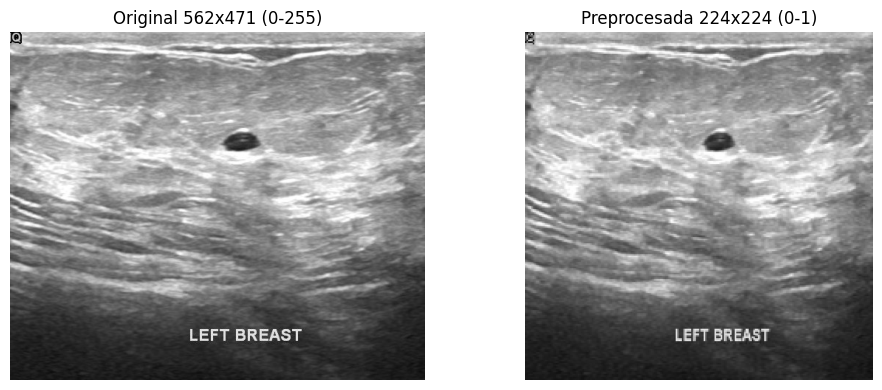

In [21]:
ruta_prueba = df_imagenes.iloc[0]["ruta_imagen"]

imagen_original = cv2.cvtColor(cv2.imread(ruta_prueba), cv2.COLOR_BGR2RGB)
imagen_procesada = preprocesar_imagen(ruta_prueba)

print("Forma original:", imagen_original.shape, "| rango:", imagen_original.min(), "-", imagen_original.max())
print("Forma procesada:", tuple(imagen_procesada.shape),
      "| rango:", round(float(tf.reduce_min(imagen_procesada)), 4), "-", round(float(tf.reduce_max(imagen_procesada)), 4))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

ejes[0].imshow(imagen_original)
ejes[0].set_title(f"Original {imagen_original.shape[1]}x{imagen_original.shape[0]} (0-255)")
ejes[0].axis("off")

ejes[1].imshow(imagen_procesada.numpy())
ejes[1].set_title("Preprocesada 224x224 (0-1)")
ejes[1].axis("off")

plt.tight_layout()
guardar_figura("fig_antes_despues_preprocesamiento.png")
plt.show()

# **6. Partición estratificada de los datos (70 % / 15 % / 15 %)**

La partición se hace en dos pasos con `stratify` para mantener la proporción de clases y `random_state=42` para que sea reproducible. El conjunto **Test** queda reservado para la evaluación final.

In [22]:
# Primera partición: 70 % Training y 30 % temporal
df_train, df_temp = train_test_split(
    df_imagenes,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=df_imagenes["clase_diagnostico"]
)

# Segunda partición: el 30 % temporal se divide en Validation y Test
df_validation, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=SEMILLA,
    stratify=df_temp["clase_diagnostico"]
)

total = len(df_imagenes)

for nombre, df in [("Training", df_train), ("Validation", df_validation), ("Test", df_test)]:
    print(f"{nombre}: {len(df)} imágenes - {len(df) / total * 100:.2f}%")

Training: 522 imágenes - 69.97%
Validation: 112 imágenes - 15.01%
Test: 112 imágenes - 15.01%


## 6.1 Verificar que la estratificación funcionó

In [23]:
tabla_particion = pd.DataFrame({
    "Training": df_train["clase_diagnostico"].value_counts(),
    "Validation": df_validation["clase_diagnostico"].value_counts(),
    "Test": df_test["clase_diagnostico"].value_counts(),
    "Total": df_imagenes["clase_diagnostico"].value_counts()
}).loc[CLASES]

tabla_particion.loc["TOTAL"] = tabla_particion.sum()

print("Cantidad de imágenes por clase y subconjunto:")
display(tabla_particion)

tabla_porcentajes = pd.DataFrame({
    "Dataset completo": df_imagenes["clase_diagnostico"].value_counts(normalize=True),
    "Training": df_train["clase_diagnostico"].value_counts(normalize=True),
    "Validation": df_validation["clase_diagnostico"].value_counts(normalize=True),
    "Test": df_test["clase_diagnostico"].value_counts(normalize=True)
}).loc[CLASES].mul(100).round(2)

print("\nPorcentaje de cada clase por subconjunto (%):")
display(tabla_porcentajes)

Cantidad de imágenes por clase y subconjunto:


,Training,Validation,Test,Total
clase_diagnostico,,,,
benign,289,62,62,413
malignant,145,31,31,207
normal,88,19,19,126
TOTAL,522,112,112,746



Porcentaje de cada clase por subconjunto (%):


,Dataset completo,Training,Validation,Test
clase_diagnostico,,,,
benign,55.36,55.36,55.36,55.36
malignant,27.75,27.78,27.68,27.68
normal,16.89,16.86,16.96,16.96


In [24]:
# Verificación final: no se perdió ni se duplicó ninguna imagen
total_particiones = len(df_train) + len(df_validation) + len(df_test)

archivos_train = set(df_train["ruta_imagen"])
archivos_val = set(df_validation["ruta_imagen"])
archivos_test = set(df_test["ruta_imagen"])

print("Total del dataset original:", len(df_imagenes))
print("Total después de la partición:", total_particiones)
print("Imágenes compartidas Train-Validation:", len(archivos_train & archivos_val))
print("Imágenes compartidas Train-Test:", len(archivos_train & archivos_test))
print("Imágenes compartidas Validation-Test:", len(archivos_val & archivos_test))

if total_particiones == len(df_imagenes) and not (archivos_train & archivos_test):
    print("\nPartición realizada correctamente y sin fuga de datos (data leakage).")
else:
    print("\nERROR: revise la partición.")

Total del dataset original: 746
Total después de la partición: 746
Imágenes compartidas Train-Validation: 0
Imágenes compartidas Train-Test: 0
Imágenes compartidas Validation-Test: 0

Partición realizada correctamente y sin fuga de datos (data leakage).


Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_particion_estratificada.png


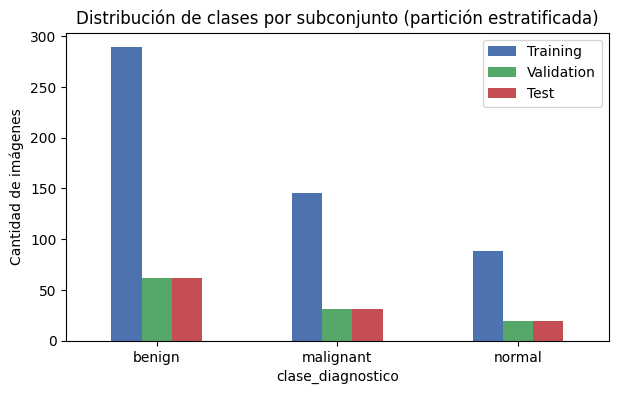

In [25]:
tabla_particion.drop("TOTAL")[["Training", "Validation", "Test"]].plot(
    kind="bar",
    figsize=(7, 4),
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Distribución de clases por subconjunto (partición estratificada)")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=0)
guardar_figura("fig_particion_estratificada.png")
plt.show()

# **7. Baseline (modelo de referencia mínimo)**

Se usa `DummyClassifier` con la estrategia `most_frequent`: siempre predice la clase mayoritaria de Training (`benign`). No mira las imágenes; solo fija el **piso** que los modelos CNN deben superar.

In [26]:
X_train_dummy = np.zeros((len(df_train), 1))
X_validation_dummy = np.zeros((len(df_validation), 1))
X_test_dummy = np.zeros((len(df_test), 1))

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_dummy, df_train["etiqueta"].values)

print("Clase mayoritaria aprendida:", CLASES[baseline.predict(X_train_dummy[:1])[0]])

for nombre, X_dummy, df in [("Validation", X_validation_dummy, df_validation), ("Test", X_test_dummy, df_test)]:

    predicciones = baseline.predict(X_dummy)

    print(f"\n{nombre}")
    print(f"  Accuracy:   {accuracy_score(df['etiqueta'], predicciones) * 100:.2f}%")
    print(f"  F1 macro:   {f1_score(df['etiqueta'], predicciones, average='macro', zero_division=0):.4f}")
    print(f"  Recall maligno: {recall_score(df['etiqueta'], predicciones, labels=[1], average='macro', zero_division=0):.4f}")

Clase mayoritaria aprendida: benign

Validation
  Accuracy:   55.36%
  F1 macro:   0.2375
  Recall maligno: 0.0000

Test
  Accuracy:   55.36%
  F1 macro:   0.2375
  Recall maligno: 0.0000


**Interpretación:** el baseline obtiene una exactitud igual a la proporción de la clase `benign` (alrededor del 56 %) solo por predecir siempre esa clase, pero su F1 macro es muy bajo y **no detecta ningún caso maligno** (recall maligno = 0). Por eso la exactitud por sí sola no es suficiente y la métrica principal del experimento es el **F1-score macro**, acompañado del **recall de la clase maligna**.

# **8. Pipeline de datos con `tf.data` y pesos de clase**

## 8.1 Construcción de los conjuntos

- Las etiquetas se convierten a *one-hot*.
- `cache()` guarda las imágenes ya preprocesadas en memoria (se leen de Drive solo una vez).
- Solo Training se baraja (`shuffle`). Validation y Test mantienen su orden para poder comparar predicciones con etiquetas reales.

In [27]:
AUTOTUNE = tf.data.AUTOTUNE

def cargar_ejemplo(ruta_imagen, etiqueta):
    imagen = preprocesar_imagen(ruta_imagen)
    etiqueta = tf.one_hot(etiqueta, NUM_CLASES)
    return imagen, etiqueta


def crear_dataset(dataframe, entrenamiento=False):

    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["ruta_imagen"].values,
        dataframe["etiqueta"].values.astype("int32")
    ))

    dataset = dataset.map(cargar_ejemplo, num_parallel_calls=AUTOTUNE)
    dataset = dataset.cache()

    if entrenamiento:
        dataset = dataset.shuffle(len(dataframe), seed=SEMILLA, reshuffle_each_iteration=True)

    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return dataset


ds_train = crear_dataset(df_train, entrenamiento=True)
ds_validation = crear_dataset(df_validation)
ds_test = crear_dataset(df_test)

imagenes_lote, etiquetas_lote = next(iter(ds_train))

print("Forma de un lote de imágenes:", imagenes_lote.shape)
print("Forma de un lote de etiquetas:", etiquetas_lote.shape)
print("Rango de píxeles del lote:", float(tf.reduce_min(imagenes_lote)), "-", float(tf.reduce_max(imagenes_lote)))

Forma de un lote de imágenes: (32, 224, 224, 3)
Forma de un lote de etiquetas: (32, 3)
Rango de píxeles del lote: 0.0 - 1.0


## 8.2 Pesos de clase (tratamiento del desbalance)

La clase `benign` tiene más del triple de imágenes que `normal`. Para que la red no favorezca a la clase mayoritaria, se asigna a cada clase un peso inversamente proporcional a su frecuencia en Training:

$$w_c = \frac{N}{K \cdot n_c}$$

donde $N$ es el total de imágenes de Training, $K = 3$ el número de clases y $n_c$ la cantidad de imágenes de la clase $c$. Los mismos pesos se usan en **ambos** modelos para que la comparación sea justa.

In [28]:
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASES),
    y=df_train["etiqueta"].values
)

PESOS_CLASE = {indice: float(peso) for indice, peso in enumerate(pesos)}

for indice, peso in PESOS_CLASE.items():
    print(f"{CLASES[indice]:>10}: {peso:.4f}")

    benign: 0.6021
 malignant: 1.2000
    normal: 1.9773


# **9. Modelos candidatos**

Se comparan dos CNN de la misma familia para medir de forma controlada el efecto de *Data Augmentation*, mayor profundidad y *Dropout*.

## 9.1 Modelo A — CNN base

Arquitectura construida desde cero, sin *Data Augmentation* ni *Dropout*.

In [29]:
def crear_modelo_a():

    modelo = Sequential([

        # Forma de entrada de las ecografías
        Input(shape=(IMG_ALTO, IMG_ANCHO, 3)),

        # Primer bloque convolucional
        Conv2D(32, kernel_size=(3, 3), activation="relu"),
        MaxPooling2D(pool_size=(2, 2)),

        # Segundo bloque convolucional
        Conv2D(64, kernel_size=(3, 3), activation="relu"),
        MaxPooling2D(pool_size=(2, 2)),

        # Tercer bloque convolucional
        Conv2D(128, kernel_size=(3, 3), activation="relu"),
        MaxPooling2D(pool_size=(2, 2)),

        # Convertir los mapas de características en un vector
        Flatten(),

        # Capa densa
        Dense(128, activation="relu"),

        # Salida para las 3 clases
        Dense(NUM_CLASES, activation="softmax")

    ], name="Modelo_A_CNN_Base")

    return modelo

## 9.2 Modelo B — CNN optimizada con transferencia de aprendizaje

El Modelo B parte de **EfficientNetB0 preentrenada en ImageNet** (más de un millón de imágenes generales). La red ya sabe detectar bordes, contornos y texturas; con las ecografías solo aprende a distinguir las tres clases. Esto **no es data leakage**: ImageNet no contiene ecografías de BUSI ni las clases del problema.

Componentes del Modelo B:

1. **Data Augmentation** (volteo, rotación y zoom), activo solo durante el entrenamiento.
2. **Rescaling(255):** EfficientNetB0 espera píxeles en el rango 0–255 y aplica su propia normalización interna; como el preprocesamiento del proyecto deja los píxeles en [0, 1], esta capa los devuelve a 0–255 sin modificar el dataset.
3. **EfficientNetB0** sin su capa de clasificación original (`include_top=False`), seguida de *Global Average Pooling*.
4. **Cabeza de clasificación** igual a la del diseño original del Modelo B: `Dense(256, ReLU)` → `Dropout(0.5)` → `Dense(3, Softmax)`.

In [30]:
from tensorflow.keras import Model
from tensorflow.keras.layers import Rescaling, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.applications import EfficientNetB0


def crear_data_augmentation():

    # Transformaciones aleatorias; Keras las aplica solo en entrenamiento
    return Sequential([
        RandomFlip("horizontal"),
        RandomRotation(0.1),
        RandomZoom(0.1)
    ], name="data_augmentation")


def crear_modelo_b():

    # Red base preentrenada en ImageNet, sin su clasificador original
    base = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_ALTO, IMG_ANCHO, 3)
    )
    base.trainable = False   # Fase 1: la red base queda congelada

    entradas = Input(shape=(IMG_ALTO, IMG_ANCHO, 3))

    # Aumento de datos (solo en entrenamiento)
    x = crear_data_augmentation()(entradas)

    # Volver los píxeles de [0, 1] a [0, 255], rango que espera EfficientNetB0
    x = Rescaling(255.0, name="escala_0_255")(x)

    # Extracción de características con la red preentrenada
    # training=False mantiene fijas las estadísticas de BatchNormalization
    x = base(x, training=False)
    x = GlobalAveragePooling2D(name="global_average_pooling")(x)

    # Cabeza de clasificación
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.5)(x)
    salidas = Dense(NUM_CLASES, activation="softmax")(x)

    modelo = Model(entradas, salidas, name="Modelo_B_EfficientNetB0")

    return modelo, base

## 9.3 Vista previa del Data Augmentation

Se muestran variaciones aleatorias de una misma ecografía de Training.

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_data_augmentation.png


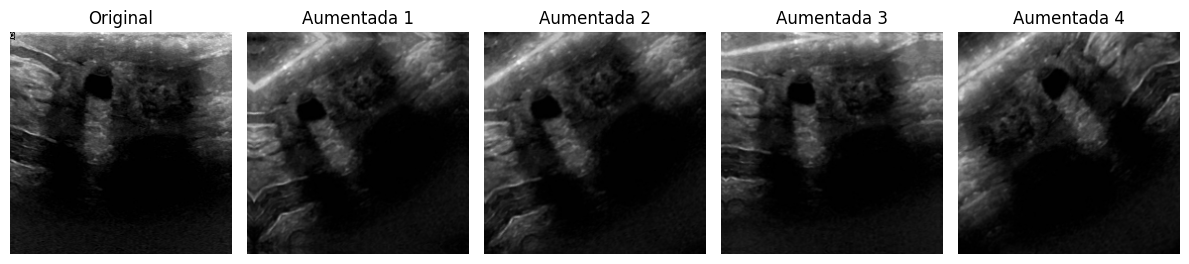

In [31]:
aumento_demo = crear_data_augmentation()
imagen_demo = imagenes_lote[0:1]

plt.figure(figsize=(12, 3))

plt.subplot(1, 5, 1)
plt.imshow(imagen_demo[0].numpy())
plt.title("Original")
plt.axis("off")

for i in range(4):
    aumentada = aumento_demo(imagen_demo, training=True)
    plt.subplot(1, 5, i + 2)
    plt.imshow(np.clip(aumentada[0].numpy(), 0, 1))
    plt.title(f"Aumentada {i + 1}")
    plt.axis("off")

plt.tight_layout()
guardar_figura("fig_data_augmentation.png")
plt.show()

## 9.4 Estructura de los modelos

In [32]:
modelo_a = crear_modelo_a()
modelo_a.summary()

Model: "Modelo_A_CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
modelo_b, base_b = crear_modelo_b()
modelo_b.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Modelo_B_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_0_255 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,278 (16.70 MB)

 Trainable params: 328,707 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [34]:
def contar_parametros(modelo):
    entrenables = int(sum(np.prod(v.shape) for v in modelo.trainable_weights))
    no_entrenables = int(sum(np.prod(v.shape) for v in modelo.non_trainable_weights))
    return entrenables, no_entrenables


for nombre, modelo in [("Modelo A", modelo_a), ("Modelo B (fase 1, base congelada)", modelo_b)]:
    entrenables, no_entrenables = contar_parametros(modelo)
    print(f"{nombre}")
    print(f"  Parámetros totales:        {modelo.count_params():,}")
    print(f"  Parámetros entrenables:    {entrenables:,}")
    print(f"  Parámetros no entrenables: {no_entrenables:,}")
    print(f"  Entrada: {modelo.input_shape} | Salida: {modelo.output_shape}\n")

print("Capas de la red base EfficientNetB0:", len(base_b.layers))

Modelo A
  Parámetros totales:        11,169,347
  Parámetros entrenables:    11,169,347
  Parámetros no entrenables: 0
  Entrada: (None, 224, 224, 3) | Salida: (None, 3)

Modelo B (fase 1, base congelada)
  Parámetros totales:        4,378,278
  Parámetros entrenables:    328,707
  Parámetros no entrenables: 4,049,571
  Entrada: (None, 224, 224, 3) | Salida: (None, 3)

Capas de la red base EfficientNetB0: 238


**Nota:** en el Modelo B, la mayoría de parámetros pertenece a EfficientNetB0 y llega ya entrenada desde ImageNet. En la fase 1 solo se entrenan las capas nuevas de clasificación; en la fase 2 se libera una parte de la red base para ajustarla a las ecografías.

## 9.5 Hipótesis experimental

**H1 — Hipótesis alternativa:** el Modelo B (CNN optimizada con transferencia de aprendizaje, Data Augmentation y Dropout) presentará un mejor desempeño que el Modelo A y superará al baseline, según la métrica principal (**F1-score macro en Test**).

**H0 — Hipótesis nula:** el Modelo B no presentará una mejora relevante frente al Modelo A ni frente al baseline según la métrica principal.

Las hipótesis se contrastan en la sección 17 con los resultados obtenidos sobre el mismo conjunto de prueba. No se realiza una prueba estadística formal.

# **10. Configuración del entrenamiento**

Ambos modelos usan los mismos datos, la misma partición, los mismos pesos de clase, el optimizador Adam, la pérdida `categorical_crossentropy`, lotes de 32 y un **máximo de 50 épocas**. La diferencia está en la estrategia de entrenamiento:

| Configuración | Modelo A (desde cero) | Modelo B — Fase 1 (base congelada) | Modelo B — Fase 2 (ajuste fino) |
|---|---|---|---|
| Capas que se entrenan | Todas | Solo la cabeza de clasificación | Cabeza + últimas 40 capas de EfficientNetB0 (sin BatchNormalization) |
| Tasa de aprendizaje inicial | 0.0001 | 0.001 | 0.00001 |
| Épocas máximas | 50 | 20 | 30 (total B ≤ 50) |
| EarlyStopping (`val_loss`) | paciencia 10 | paciencia 5 | paciencia 8 |
| ReduceLROnPlateau | factor 0.5, paciencia 5 | factor 0.5, paciencia 3 | factor 0.5, paciencia 4 |

**Por qué dos fases:** si se libera toda la red preentrenada desde el inicio, los errores grandes de la cabeza nueva (inicializada al azar) dañarían el conocimiento previo. Primero se entrena la cabeza con la base congelada; después se ajustan las capas superiores con una tasa de aprendizaje muy baja.

Todas las decisiones se toman con **Validation**; el conjunto **Test** solo se usa una vez, en la sección 14.

In [35]:
EPOCAS = 50                 # Máximo de épocas para el Modelo A y total para el Modelo B
TASA_APRENDIZAJE = 1e-4     # Modelo A

EPOCAS_FASE_1 = 20          # Modelo B, base congelada
EPOCAS_FASE_2 = 30          # Modelo B, ajuste fino (20 + 30 = 50)
TASA_FASE_1 = 1e-3
TASA_FASE_2 = 1e-5
CAPAS_A_LIBERAR = 40


def compilar_modelo(modelo, tasa=TASA_APRENDIZAJE):

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=tasa),
        loss="categorical_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc", multi_label=False),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    return modelo


def crear_callbacks(nombre_modelo, paciencia_parada=10, paciencia_lr=5, min_lr=1e-6):

    return [
        EarlyStopping(
            monitor="val_loss",
            patience=paciencia_parada,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=paciencia_lr,
            min_lr=min_lr,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=os.path.join(ruta_resultados, f"{nombre_modelo}_mejor.keras"),
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

print("Configuración lista.")

Configuración lista.


# **11. Entrenamiento del Modelo A (CNN base)**

In [36]:
tf.keras.utils.set_random_seed(SEMILLA)

modelo_a = compilar_modelo(crear_modelo_a())

inicio = time.time()

historia_a = modelo_a.fit(
    ds_train,
    validation_data=ds_validation,
    epochs=EPOCAS,
    class_weight=PESOS_CLASE,
    callbacks=crear_callbacks("modelo_a"),
    verbose=1
)

tiempo_a = time.time() - inicio
print(f"\nTiempo de entrenamiento del Modelo A: {tiempo_a / 60:.2f} minutos")
print("Épocas ejecutadas:", len(historia_a.history["loss"]))

Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 707ms/step - accuracy: 0.3831 - auc: 0.5724 - loss: 1.1155 - recall: 0.0019 - val_accuracy: 0.1964 - val_auc: 0.3567 - val_loss: 1.1222 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.3736 - auc: 0.4762 - loss: 1.0869 - recall: 0.0000e+00 - val_accuracy: 0.6161 - val_auc: 0.7413 - val_loss: 1.0623 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.6322 - auc: 0.7939 - loss: 1.0572 - recall: 0.0134 - val_accuracy: 0.6696 - val_auc: 0.7752 - val_loss: 0.9886 - val_recall: 0.0446 - learning_rate: 1.0000e-04
Epoch 4/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.6475 - auc: 0.7913 - loss: 1.0033 - recall: 0.0996 - val_accuracy: 0.5893 - val_auc: 0.7415 - val_loss: 0.9714 - val_recall: 0.1518 - learning_rate: 1.0000e-04
Epoch 5/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.6322 - auc: 0.7834

# **12. Entrenamiento del Modelo B (transferencia de aprendizaje)**

## 12.1 Fase 1 — Base congelada (entrenamiento de la cabeza de clasificación)

In [37]:
tf.keras.utils.set_random_seed(SEMILLA)

modelo_b, base_b = crear_modelo_b()
modelo_b = compilar_modelo(modelo_b, TASA_FASE_1)

inicio = time.time()

historia_b1 = modelo_b.fit(
    ds_train,
    validation_data=ds_validation,
    epochs=EPOCAS_FASE_1,
    class_weight=PESOS_CLASE,
    callbacks=crear_callbacks("modelo_b_fase1", paciencia_parada=5, paciencia_lr=3),
    verbose=1
)

tiempo_b1 = time.time() - inicio
print(f"\nTiempo de la fase 1: {tiempo_b1 / 60:.2f} minutos")
print("Épocas ejecutadas en la fase 1:", len(historia_b1.history["loss"]))
print("Menor val_loss en la fase 1:", round(min(historia_b1.history["val_loss"]), 4))

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 353ms/step - accuracy: 0.4598 - auc: 0.6492 - loss: 1.0740 - recall: 0.3257 - val_accuracy: 0.7411 - val_auc: 0.8801 - val_loss: 0.6769 - val_recall: 0.6161 - learning_rate: 0.0010
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - accuracy: 0.6264 - auc: 0.8103 - loss: 0.8021 - recall: 0.5307 - val_accuracy: 0.8214 - val_auc: 0.9159 - val_loss: 0.5986 - val_recall: 0.6518 - learning_rate: 0.0010
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.6513 - auc: 0.8366 - loss: 0.7274 - recall: 0.5766 - val_accuracy: 0.7768 - val_auc: 0.9143 - val_loss: 0.5869 - val_recall: 0.7054 - learning_rate: 0.0010
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - accuracy: 0.6839 - auc: 0.8535 - loss: 0.6982 - recall: 0.6034 - val_accuracy: 0.7946 - val_auc: 0.9303 - val_loss: 0.5339 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 0.7088 - auc: 0.8681 - loss: 0.6628 - recall: 0.

## 12.2 Fase 2 — Ajuste fino (*fine-tuning*) de las capas superiores

Se liberan las últimas 40 capas de EfficientNetB0, excepto las de `BatchNormalization`, que permanecen congeladas para no alterar sus estadísticas aprendidas. El modelo se vuelve a compilar con una tasa de aprendizaje 100 veces menor.

In [38]:
base_b.trainable = True

for capa in base_b.layers[:-CAPAS_A_LIBERAR]:
    capa.trainable = False

for capa in base_b.layers:
    if isinstance(capa, BatchNormalization):
        capa.trainable = False

capas_liberadas = sum(capa.trainable for capa in base_b.layers)
print("Capas de EfficientNetB0 liberadas para el ajuste fino:", capas_liberadas)

modelo_b = compilar_modelo(modelo_b, TASA_FASE_2)

entrenables, no_entrenables = contar_parametros(modelo_b)
print(f"Parámetros entrenables en la fase 2: {entrenables:,}")
print(f"Parámetros no entrenables en la fase 2: {no_entrenables:,}")

inicio = time.time()

historia_b2 = modelo_b.fit(
    ds_train,
    validation_data=ds_validation,
    epochs=EPOCAS_FASE_2,
    class_weight=PESOS_CLASE,
    callbacks=crear_callbacks("modelo_b_fase2", paciencia_parada=8, paciencia_lr=4, min_lr=1e-7),
    verbose=1
)

tiempo_b2 = time.time() - inicio
tiempo_b = tiempo_b1 + tiempo_b2

print(f"\nTiempo de la fase 2: {tiempo_b2 / 60:.2f} minutos")
print(f"Tiempo total del Modelo B: {tiempo_b / 60:.2f} minutos")
print("Épocas ejecutadas en la fase 2:", len(historia_b2.history["loss"]))
print("Menor val_loss en la fase 2:", round(min(historia_b2.history["val_loss"]), 4))

Capas de EfficientNetB0 liberadas para el ajuste fino: 32
Parámetros entrenables en la fase 2: 2,366,227
Parámetros no entrenables en la fase 2: 2,012,051
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 323ms/step - accuracy: 0.7682 - auc: 0.9211 - loss: 0.5283 - recall: 0.7126 - val_accuracy: 0.7768 - val_auc: 0.9373 - val_loss: 0.4968 - val_recall: 0.7411 - learning_rate: 1.0000e-05
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.7759 - auc: 0.9185 - loss: 0.5171 - recall: 0.7031 - val_accuracy: 0.7857 - val_auc: 0.9340 - val_loss: 0.5042 - val_recall: 0.7589 - learning_rate: 1.0000e-05
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.7701 - auc: 0.9212 - loss: 0.5087 - recall: 0.7203 - val_accuracy: 0.8036 - val_auc: 0.9349 - val_loss: 0.5018 - val_recall: 0.7679 - learning_rate: 1.0000e-05
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 155ms/step - accuracy: 0.7874 - auc: 0.9264 - loss: 0.4993 - recall: 0.7261 - val_accuracy: 0.7946 - val_auc: 0.9406 - val_lo

In [39]:
# Unir el historial de ambas fases para analizarlo como un solo entrenamiento
from types import SimpleNamespace

claves_comunes = [clave for clave in historia_b1.history if clave in historia_b2.history]

historia_b = SimpleNamespace(history={
    clave: list(historia_b1.history[clave]) + list(historia_b2.history[clave])
    for clave in claves_comunes
})

EPOCAS_FASE_1_EJECUTADAS = len(historia_b1.history["loss"])

print("Épocas totales del Modelo B:", len(historia_b.history["loss"]))
print("Fase 1:", EPOCAS_FASE_1_EJECUTADAS, "| Fase 2:", len(historia_b2.history["loss"]))

Épocas totales del Modelo B: 44
Fase 1: 14 | Fase 2: 30


# **13. Curvas de aprendizaje y análisis de sobreajuste**

Si la pérdida de validación se separa de la de entrenamiento, el modelo memoriza los datos (sobreajuste). El criterio de éxito 3 exige que esa brecha sea menor en el Modelo B. En las curvas del Modelo B, la línea discontinua marca el inicio del ajuste fino (fase 2).

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_curvas_aprendizaje.png


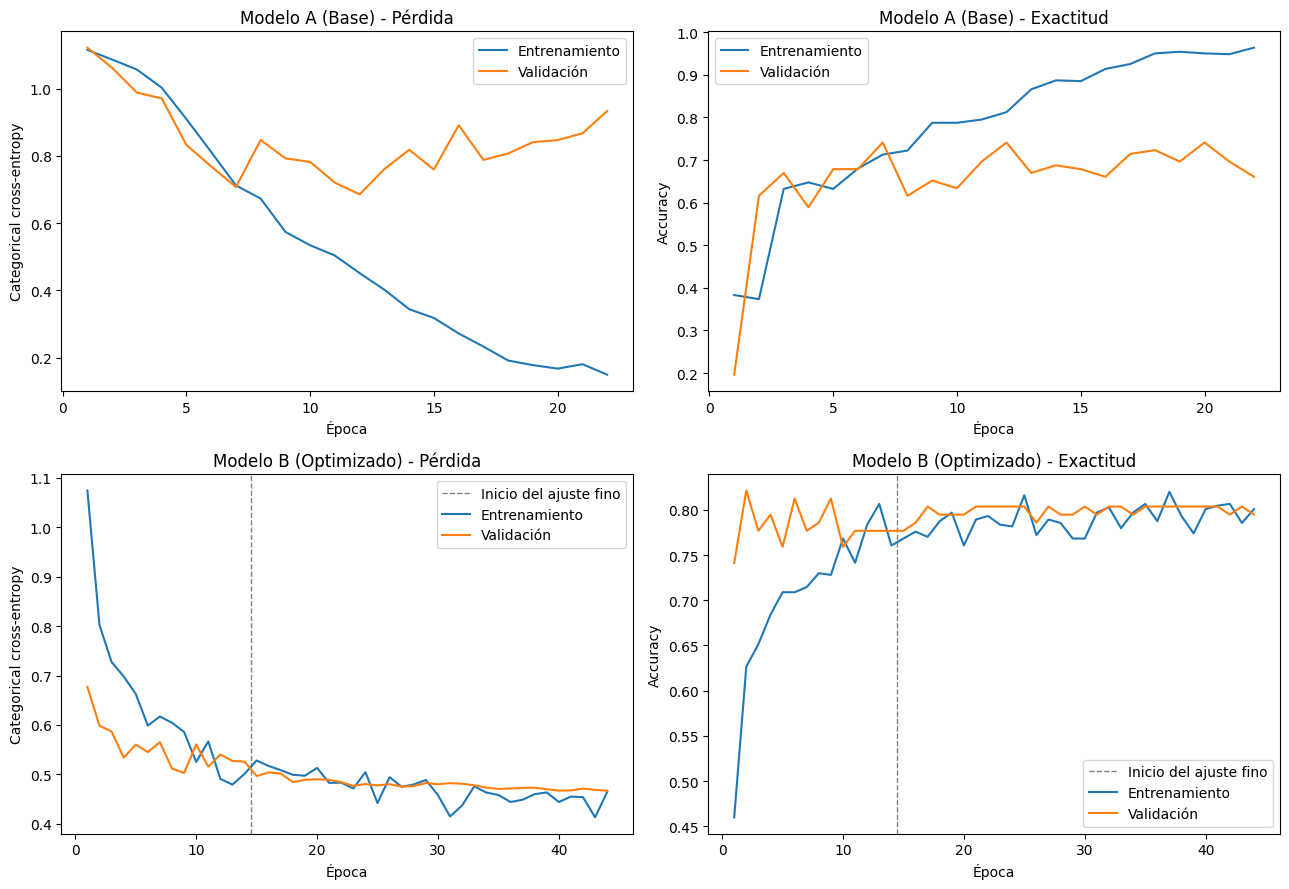

In [40]:
def graficar_curvas(historias, nombres, cortes=None):

    fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
    cortes = cortes or [None] * len(historias)

    for fila, (historia, nombre, corte) in enumerate(zip(historias, nombres, cortes)):

        epocas = range(1, len(historia["loss"]) + 1)

        if corte:
            for columna in range(2):
                ejes[fila, columna].axvline(corte + 0.5, color="gray", linestyle="--", linewidth=1,
                                             label="Inicio del ajuste fino")

        ejes[fila, 0].plot(epocas, historia["loss"], label="Entrenamiento")
        ejes[fila, 0].plot(epocas, historia["val_loss"], label="Validación")
        ejes[fila, 0].set_title(f"{nombre} - Pérdida")
        ejes[fila, 0].set_xlabel("Época")
        ejes[fila, 0].set_ylabel("Categorical cross-entropy")
        ejes[fila, 0].legend()

        ejes[fila, 1].plot(epocas, historia["accuracy"], label="Entrenamiento")
        ejes[fila, 1].plot(epocas, historia["val_accuracy"], label="Validación")
        ejes[fila, 1].set_title(f"{nombre} - Exactitud")
        ejes[fila, 1].set_xlabel("Época")
        ejes[fila, 1].set_ylabel("Accuracy")
        ejes[fila, 1].legend()

    plt.tight_layout()


graficar_curvas([historia_a.history, historia_b.history], ["Modelo A (Base)", "Modelo B (Optimizado)"],
                cortes=[None, EPOCAS_FASE_1_EJECUTADAS])
guardar_figura("fig_curvas_aprendizaje.png")
plt.show()

In [41]:
def resumen_sobreajuste(historia, nombre):

    mejor = int(np.argmin(historia["val_loss"]))

    return {
        "Modelo": nombre,
        "Épocas ejecutadas": len(historia["loss"]),
        "Mejor época": mejor + 1,
        "Loss train (mejor época)": round(historia["loss"][mejor], 4),
        "Loss val (mejor época)": round(historia["val_loss"][mejor], 4),
        "Brecha loss (val - train)": round(historia["val_loss"][mejor] - historia["loss"][mejor], 4),
        "Brecha loss final (val - train)": round(historia["val_loss"][-1] - historia["loss"][-1], 4),
        "Acc train (mejor época)": round(historia["accuracy"][mejor], 4),
        "Acc val (mejor época)": round(historia["val_accuracy"][mejor], 4)
    }


tabla_sobreajuste = pd.DataFrame([
    resumen_sobreajuste(historia_a.history, "Modelo A"),
    resumen_sobreajuste(historia_b.history, "Modelo B")
]).set_index("Modelo")

tabla_sobreajuste.T

Modelo,Modelo A,Modelo B
Épocas ejecutadas,22.0000,44.0000
Mejor época,12.0000,44.0000
Loss train (mejor época),0.4515,0.4649
Loss val (mejor época),0.6859,0.4671
Brecha loss (val - train),0.2344,0.0021
Brecha loss final (val - train),0.7843,0.0021
Acc train (mejor época),0.8123,0.8008
Acc val (mejor época),0.7411,0.7946


# **14. Evaluación final en el conjunto Test**

El conjunto Test no se usó en ningún momento del entrenamiento ni en la toma de decisiones. En esta sección se calculan las métricas definidas en el diseño experimental:

- **Exactitud (accuracy)**
- **Precisión, sensibilidad (recall) y F1-score macro** (promedio de las 3 clases, sin favorecer a la mayoritaria)
- **Sensibilidad de la clase maligna** (la más crítica clínicamente)
- **AUC macro uno-contra-resto**

In [42]:
y_test = df_test["etiqueta"].values
y_test_onehot = tf.keras.utils.to_categorical(y_test, NUM_CLASES)

probabilidades_a = modelo_a.predict(ds_test, verbose=0)
probabilidades_b = modelo_b.predict(ds_test, verbose=0)

prediccion_a = probabilidades_a.argmax(axis=1)
prediccion_b = probabilidades_b.argmax(axis=1)

# Baseline en Test (probabilidad 1 para la clase mayoritaria)
prediccion_baseline = baseline.predict(X_test_dummy)
probabilidades_baseline = tf.keras.utils.to_categorical(prediccion_baseline, NUM_CLASES)

print("Predicciones obtenidas:", probabilidades_a.shape, probabilidades_b.shape)

Predicciones obtenidas: (112, 3) (112, 3)


In [43]:
def calcular_metricas(y_real, y_pred, probabilidades, nombre):

    try:
        auc_macro = roc_auc_score(
            tf.keras.utils.to_categorical(y_real, NUM_CLASES),
            probabilidades,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        auc_macro = np.nan

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall maligno": recall_score(y_real, y_pred, labels=[CLASE_A_INDICE["malignant"]], average="macro", zero_division=0),
        "AUC macro (OvR)": auc_macro
    }


tabla_metricas = pd.DataFrame([
    calcular_metricas(y_test, prediccion_baseline, probabilidades_baseline, "Baseline (Dummy)"),
    calcular_metricas(y_test, prediccion_a, probabilidades_a, "Modelo A (Base)"),
    calcular_metricas(y_test, prediccion_b, probabilidades_b, "Modelo B (Optimizado)")
]).set_index("Modelo").round(4)

tabla_metricas

,Accuracy,Precision macro,Recall macro,F1 macro,Recall maligno,AUC macro (OvR)
Modelo,,,,,,
Baseline (Dummy),0.5536,0.1845,0.3333,0.2375,0.0000,0.5000
Modelo A (Base),0.6518,0.6018,0.6163,0.6057,0.6129,0.8391
Modelo B (Optimizado),0.7679,0.7511,0.8022,0.7635,0.8710,0.9266


In [44]:
print("=" * 60)
print("REPORTE DE CLASIFICACIÓN - MODELO A (BASE)")
print("=" * 60)
print(classification_report(y_test, prediccion_a, target_names=CLASES, digits=4, zero_division=0))

print("=" * 60)
print("REPORTE DE CLASIFICACIÓN - MODELO B (OPTIMIZADO)")
print("=" * 60)
print(classification_report(y_test, prediccion_b, target_names=CLASES, digits=4, zero_division=0))

REPORTE DE CLASIFICACIÓN - MODELO A (BASE)
              precision    recall  f1-score   support

      benign     0.7719    0.7097    0.7395        62
   malignant     0.6333    0.6129    0.6230        31
      normal     0.4000    0.5263    0.4545        19

    accuracy                         0.6518       112
   macro avg     0.6018    0.6163    0.6057       112
weighted avg     0.6705    0.6518    0.6589       112

REPORTE DE CLASIFICACIÓN - MODELO B (OPTIMIZADO)
              precision    recall  f1-score   support

      benign     0.9149    0.6935    0.7890        62
   malignant     0.6429    0.8710    0.7397        31
      normal     0.6957    0.8421    0.7619        19

    accuracy                         0.7679       112
   macro avg     0.7511    0.8022    0.7635       112
weighted avg     0.8024    0.7679    0.7708       112



# **15. Matrices de confusión**

Las filas son la clase real y las columnas la clase predicha. La diagonal son los aciertos. En contexto clínico, el error más grave es un caso **maligno** predicho como benigno o normal (falso negativo).

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_matrices_confusion.png


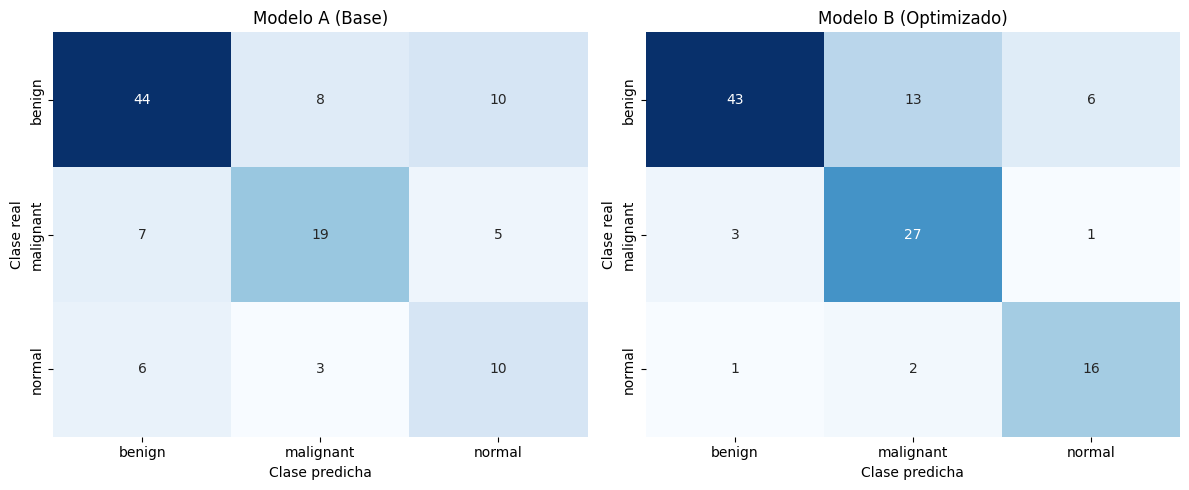

In [45]:
def graficar_matrices(y_real, predicciones, nombres):

    fig, ejes = plt.subplots(1, len(predicciones), figsize=(6 * len(predicciones), 5))

    for eje, y_pred, nombre in zip(np.atleast_1d(ejes), predicciones, nombres):

        matriz = confusion_matrix(y_real, y_pred, labels=range(NUM_CLASES))

        sns.heatmap(
            matriz,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASES,
            yticklabels=CLASES,
            cbar=False,
            ax=eje
        )

        eje.set_title(nombre)
        eje.set_xlabel("Clase predicha")
        eje.set_ylabel("Clase real")

    plt.tight_layout()


graficar_matrices(y_test, [prediccion_a, prediccion_b], ["Modelo A (Base)", "Modelo B (Optimizado)"])
guardar_figura("fig_matrices_confusion.png")
plt.show()

# **16. Curvas ROC y AUC por clase (uno contra el resto)**

Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_curvas_roc.png


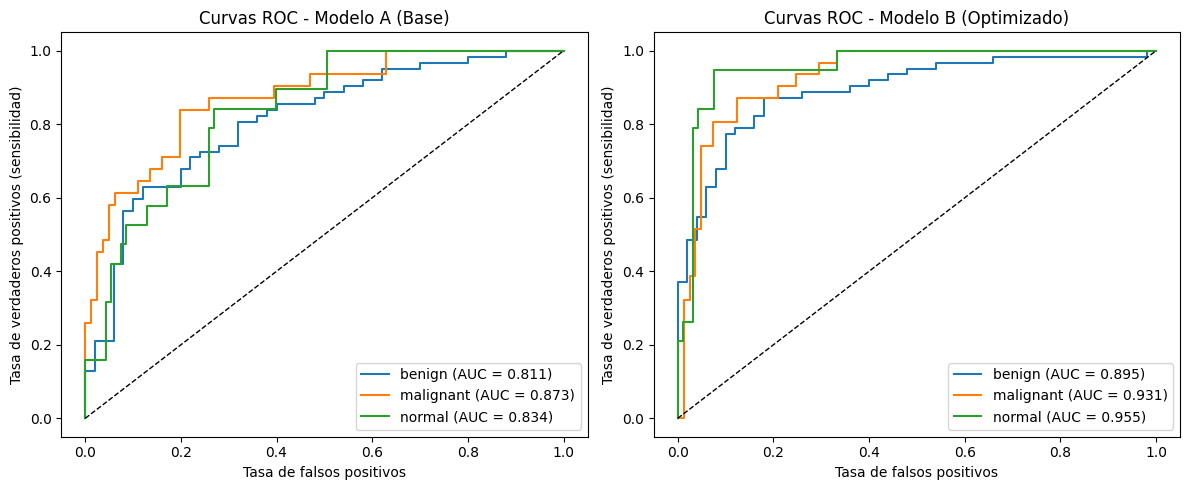

In [46]:
def graficar_roc(y_real, lista_probabilidades, nombres):

    y_onehot = tf.keras.utils.to_categorical(y_real, NUM_CLASES)

    fig, ejes = plt.subplots(1, len(lista_probabilidades), figsize=(6 * len(lista_probabilidades), 5))

    for eje, probabilidades, nombre in zip(np.atleast_1d(ejes), lista_probabilidades, nombres):

        for indice, clase in enumerate(CLASES):

            fpr, tpr, _ = roc_curve(y_onehot[:, indice], probabilidades[:, indice])
            eje.plot(fpr, tpr, label=f"{clase} (AUC = {auc(fpr, tpr):.3f})")

        eje.plot([0, 1], [0, 1], "k--", linewidth=1)
        eje.set_title(f"Curvas ROC - {nombre}")
        eje.set_xlabel("Tasa de falsos positivos")
        eje.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
        eje.legend(loc="lower right")

    plt.tight_layout()


graficar_roc(y_test, [probabilidades_a, probabilidades_b], ["Modelo A (Base)", "Modelo B (Optimizado)"])
guardar_figura("fig_curvas_roc.png")
plt.show()

# **17. Comparación final, criterios de éxito e hipótesis**

In [ ]:
metricas_a = tabla_metricas.loc["Modelo A (Base)"]
metricas_b = tabla_metricas.loc["Modelo B (Optimizado)"]
metricas_base = tabla_metricas.loc["Baseline (Dummy)"]

brecha_a = tabla_sobreajuste.loc["Modelo A", "Brecha loss (val - train)"]
brecha_b = tabla_sobreajuste.loc["Modelo B", "Brecha loss (val - train)"]

criterios = pd.DataFrame([
    {
        "Criterio de éxito": "1. Operatividad técnica (ambos modelos entrenan y predicen)",
        "Valor obtenido": f"A: {len(prediccion_a)} predicciones | B: {len(prediccion_b)} predicciones",
        "¿Cumple?": "Sí" if (len(prediccion_a) == len(y_test) and len(prediccion_b) == len(y_test)
                            and not np.isnan(historia_b.history["loss"]).any()) else "No"
    },
    {
        "Criterio de éxito": "2. Exactitud del Modelo B en Test > 75 %",
        "Valor obtenido": f"{metricas_b['Accuracy'] * 100:.2f} %",
        "¿Cumple?": "Sí" if metricas_b["Accuracy"] > 0.75 else "No"
    },
    {
        "Criterio de éxito": "2. F1 macro y sensibilidad del Modelo B superiores al Modelo A",
        "Valor obtenido": f"F1: {metricas_b['F1 macro']:.4f} vs {metricas_a['F1 macro']:.4f} | "
                          f"Recall: {metricas_b['Recall macro']:.4f} vs {metricas_a['Recall macro']:.4f}",
        "¿Cumple?": "Sí" if (metricas_b["F1 macro"] > metricas_a["F1 macro"]
                            and metricas_b["Recall macro"] > metricas_a["Recall macro"]) else "No"
    },
    {
        "Criterio de éxito": "3. Menor brecha de pérdida (val - train) en el Modelo B",
        "Valor obtenido": f"B: {brecha_b:.4f} vs A: {brecha_a:.4f}",
        "¿Cumple?": "Sí" if brecha_b < brecha_a else "No"
    }
])

pd.set_option("display.max_colwidth", None)
criterios

In [48]:
print("CONTRASTE DE HIPÓTESIS (métrica principal: F1 macro en Test)\n")
print(f"Baseline: {metricas_base['F1 macro']:.4f}")
print(f"Modelo A: {metricas_a['F1 macro']:.4f}")
print(f"Modelo B: {metricas_b['F1 macro']:.4f}")

if metricas_b["F1 macro"] > metricas_a["F1 macro"] and metricas_b["F1 macro"] > metricas_base["F1 macro"]:
    print("\nSe acepta H1: el Modelo B supera al Modelo A y al baseline.")
else:
    print("\nNo se acepta H1 (se mantiene H0): el Modelo B no supera a ambos referentes.")

CONTRASTE DE HIPÓTESIS (métrica principal: F1 macro en Test)

Baseline: 0.2375
Modelo A: 0.6057
Modelo B: 0.7635

Se acepta H1: el Modelo B supera al Modelo A y al baseline.


In [ ]:
tabla_metricas.drop(columns=["AUC macro (OvR)"]).T.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#999999", "#4C72B0", "#C44E52"]
)

plt.axhline(0.75, color="black", linestyle="--", linewidth=1, label="Umbral de exactitud 75 %")
plt.title("Comparación de métricas en Test")
plt.ylabel("Valor")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
guardar_figura("fig_comparacion_metricas.png")
plt.show()

# **18. Análisis de errores**

Se muestran las ecografías de Test que el mejor modelo clasificó mal, con la probabilidad asignada. Esto ayuda a entender en qué tipo de imágenes falla la red.

In [50]:
if metricas_b["F1 macro"] >= metricas_a["F1 macro"]:
    mejor_nombre, mejor_modelo, mejor_probabilidades = "Modelo B", modelo_b, probabilidades_b
else:
    mejor_nombre, mejor_modelo, mejor_probabilidades = "Modelo A", modelo_a, probabilidades_a

mejor_prediccion = mejor_probabilidades.argmax(axis=1)

df_errores = df_test.copy()
df_errores["prediccion"] = [CLASES[i] for i in mejor_prediccion]
df_errores["confianza"] = mejor_probabilidades.max(axis=1).round(3)
df_errores = df_errores[df_errores["prediccion"] != df_errores["clase_diagnostico"]]

print(f"Mejor modelo: {mejor_nombre}")
print(f"Imágenes mal clasificadas: {len(df_errores)} de {len(df_test)}\n")

print("Tipos de error (real -> predicho):")
print(df_errores.groupby(["clase_diagnostico", "prediccion"]).size().sort_values(ascending=False))

Mejor modelo: Modelo B
Imágenes mal clasificadas: 26 de 112

Tipos de error (real -> predicho):
clase_diagnostico  prediccion
benign             malignant     13
                   normal         6
malignant          benign         3
normal             malignant      2
malignant          normal         1
normal             benign         1
dtype: int64


Figura guardada en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2/fig_analisis_errores.png


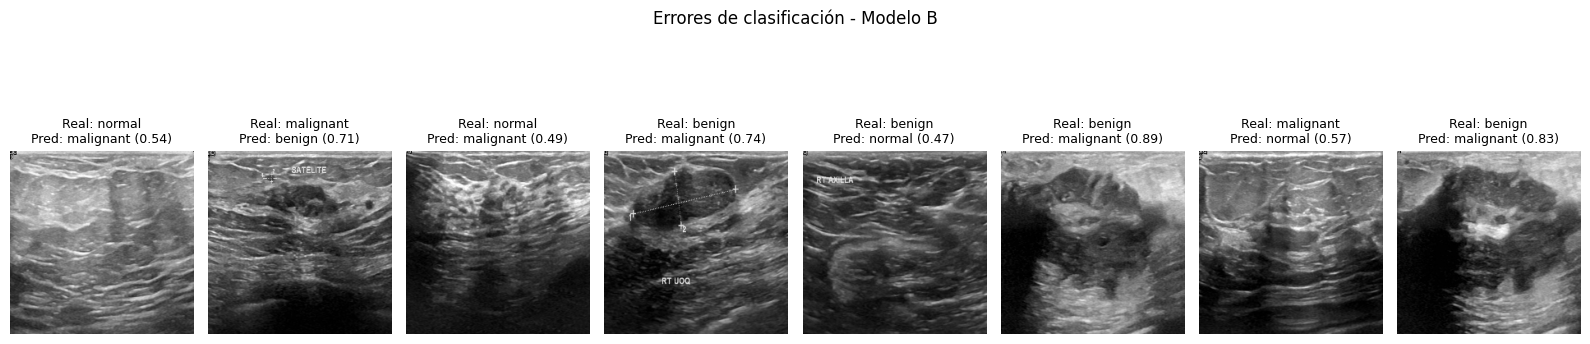

In [51]:
cantidad = min(8, len(df_errores))

if cantidad > 0:

    plt.figure(figsize=(16, 4.5))

    for i, (_, fila) in enumerate(df_errores.head(cantidad).iterrows()):

        imagen = preprocesar_imagen(fila["ruta_imagen"]).numpy()

        plt.subplot(1, cantidad, i + 1)
        plt.imshow(imagen)
        plt.title(f"Real: {fila['clase_diagnostico']}\nPred: {fila['prediccion']} ({fila['confianza']:.2f})", fontsize=9)
        plt.axis("off")

    plt.suptitle(f"Errores de clasificación - {mejor_nombre}")
    plt.tight_layout()
    guardar_figura("fig_analisis_errores.png")
    plt.show()

else:
    print("El modelo no cometió errores en Test.")

# **19. Guardado de modelos y resultados**

Los modelos y tablas quedan en `MyDrive/DataSetKaggle/resultados_proyecto_v2` para usarlos en la sección IV. Resultados del informe.

In [52]:
modelo_a.save(os.path.join(ruta_resultados, "modelo_a_final.keras"))
modelo_b.save(os.path.join(ruta_resultados, "modelo_b_final.keras"))

tabla_metricas.to_csv(os.path.join(ruta_resultados, "metricas_test.csv"))
tabla_sobreajuste.to_csv(os.path.join(ruta_resultados, "resumen_sobreajuste.csv"))
criterios.to_csv(os.path.join(ruta_resultados, "criterios_exito.csv"), index=False)
tabla_particion.to_csv(os.path.join(ruta_resultados, "particion_por_clase.csv"))

pd.DataFrame(historia_a.history).to_csv(os.path.join(ruta_resultados, "historia_modelo_a.csv"), index_label="epoca")
pd.DataFrame(historia_b.history).to_csv(os.path.join(ruta_resultados, "historia_modelo_b.csv"), index_label="epoca")
df_depuracion.to_csv(os.path.join(ruta_resultados, "imagenes_eliminadas_duplicados.csv"), index=False)
tabla_depuracion.to_csv(os.path.join(ruta_resultados, "depuracion_por_clase.csv"))

pd.DataFrame([
    {"Modelo": "Modelo A", "Tiempo (min)": round(tiempo_a / 60, 2), "Épocas": len(historia_a.history["loss"])},
    {"Modelo": "Modelo B - fase 1", "Tiempo (min)": round(tiempo_b1 / 60, 2), "Épocas": len(historia_b1.history["loss"])},
    {"Modelo": "Modelo B - fase 2", "Tiempo (min)": round(tiempo_b2 / 60, 2), "Épocas": len(historia_b2.history["loss"])}
]).to_csv(os.path.join(ruta_resultados, "tiempos_entrenamiento.csv"), index=False)

print("Archivos guardados en:", ruta_resultados)
for archivo in sorted(os.listdir(ruta_resultados)):
    print(" -", archivo)

Archivos guardados en: /content/drive/MyDrive/DataSetKaggle/resultados_proyecto_v2
 - criterios_exito.csv
 - depuracion_por_clase.csv
 - fig_analisis_errores.png
 - fig_antes_despues_preprocesamiento.png
 - fig_comparacion_metricas.png
 - fig_curvas_aprendizaje.png
 - fig_curvas_roc.png
 - fig_data_augmentation.png
 - fig_distribucion_clases.png
 - fig_duplicados.png
 - fig_ejemplos_por_clase.png
 - fig_matrices_confusion.png
 - fig_particion_estratificada.png
 - historia_modelo_a.csv
 - historia_modelo_b.csv
 - imagenes_eliminadas_duplicados.csv
 - metricas_test.csv
 - modelo_a_final.keras
 - modelo_a_mejor.keras
 - modelo_b_fase1_mejor.keras
 - modelo_b_fase2_mejor.keras
 - modelo_b_final.keras
 - particion_por_clase.csv
 - resumen_sobreajuste.csv
 - tiempos_entrenamiento.csv


# **20. Prototipo de inferencia (apoyo al diagnóstico)**

Función que recibe la ruta de una ecografía y devuelve la clase predicha con la probabilidad de cada clase. **Es solo una herramienta de apoyo**: la decisión diagnóstica final corresponde al médico especialista.

Clase real: malignant


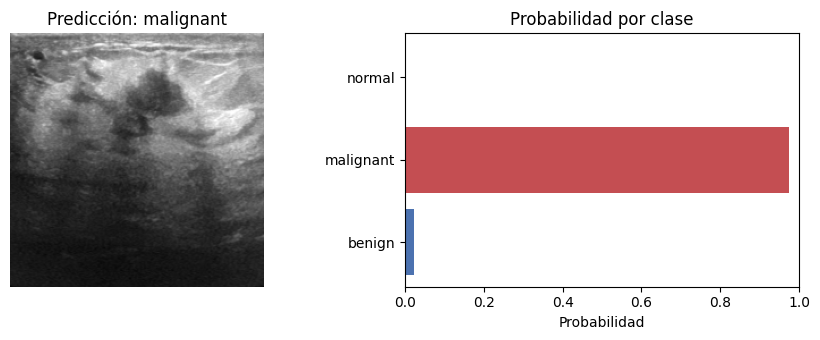

('malignant',
 {'benign': np.float32(0.0223),
  'malignant': np.float32(0.9751),
  'normal': np.float32(0.0027)})

In [53]:
def diagnosticar_ecografia(ruta_imagen, modelo=mejor_modelo):

    imagen = preprocesar_imagen(ruta_imagen)
    probabilidades = modelo.predict(tf.expand_dims(imagen, 0), verbose=0)[0]

    clase = CLASES[int(np.argmax(probabilidades))]

    plt.figure(figsize=(9, 3.5))

    plt.subplot(1, 2, 1)
    plt.imshow(imagen.numpy())
    plt.title(f"Predicción: {clase}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.barh(CLASES, probabilidades, color=["#4C72B0", "#C44E52", "#55A868"])
    plt.xlim(0, 1)
    plt.xlabel("Probabilidad")
    plt.title("Probabilidad por clase")

    plt.tight_layout()
    plt.show()

    return clase, dict(zip(CLASES, probabilidades.round(4)))


# Ejemplo con una imagen del conjunto Test
ejemplo = df_test.iloc[0]
print("Clase real:", ejemplo["clase_diagnostico"])
diagnosticar_ecografia(ejemplo["ruta_imagen"])

# **21. Conclusiones del experimento**

Resultados de la ejecución del 29 de octubre de 2026 (GPU NVIDIA Tesla T4), con la muestra depurada de 746 ecografías y un conjunto de prueba de 112 imágenes.

| Modelo | Accuracy | Precision macro | Recall macro | F1 macro | Recall maligno | AUC macro |
|---|---|---|---|---|---|---|
| Baseline (Dummy) | 0.5536 | 0.1845 | 0.3333 | 0.2375 | 0.0000 | 0.5000 |
| Modelo A (desde cero) | 0.6518 | 0.6018 | 0.6163 | 0.6057 | 0.6129 | 0.8391 |
| Modelo B (EfficientNetB0) | **0.7679** | **0.7511** | **0.8022** | **0.7635** | **0.8710** | **0.9266** |

- **Calidad de los datos:** la detección por contenido encontró 27 grupos de ecografías duplicadas en BUSI, entre ellos dos imágenes registradas a la vez como benignas y malignas. Se eliminaron 34 imágenes antes de la partición. Sin esta depuración, algunas copias habrían quedado en entrenamiento y en prueba, y las métricas habrían salido infladas por fuga de datos.
- **Desempeño del Modelo A:** alcanzó una exactitud de 65.18 % y un F1 macro de 0.6057. Mostró un sobreajuste marcado: su exactitud de entrenamiento llegó a 96 % mientras la de validación se mantuvo cerca del 70 %, y la brecha final de pérdida fue de 0.7843.
- **Desempeño del Modelo B:** obtuvo el mejor resultado en todas las métricas. Su F1 macro (0.7635) supera en 0.16 al del Modelo A, y su AUC macro (0.9266) indica una buena capacidad para separar las tres clases. Mejoró el F1-score de las tres clases y la sensibilidad de las clases `malignant` y `normal`; en esta última, la sensibilidad pasó de 0.5263 en el Modelo A a 0.8421 en el Modelo B. En la clase `benign`, su sensibilidad fue ligeramente menor que la del Modelo A (0.6935 en el Modelo B frente a 0.7097 en el Modelo A), aunque con una precisión mucho mayor (0.9149 frente a 0.7719).
- **Detección de casos malignos:** el Modelo B identificó 27 de los 31 tumores malignos del conjunto de prueba (sensibilidad de 0.8710 en el Modelo B frente a 0.6129 en el Modelo A). Su error más frecuente fue clasificar lesiones benignas como malignas (13 casos), un error menos grave en la práctica clínica que pasar por alto un cáncer, aunque genera revisiones adicionales.
- **Criterio de exactitud:** el Modelo B alcanzó una exactitud de 76.79 % en Test, superior al umbral de 75 % definido como criterio de éxito. La segunda parte del criterio 2 también se cumple: el Modelo B obtuvo un F1 macro de 0.7635 y una sensibilidad macro de 0.8022, ambos superiores a los del Modelo A (0.6057 y 0.6163, respectivamente).
- **Sobreajuste:** se redujo de forma notable. En la mejor época, la brecha entre pérdida de validación y de entrenamiento fue de 0.0021 en el Modelo B, frente a 0.2344 en el Modelo A; las curvas del Modelo B avanzan juntas durante todo el entrenamiento.
- **Contraste de hipótesis:** se acepta H1 de forma descriptiva, ya que el F1 macro del Modelo B (0.7635) supera al del Modelo A (0.6057) y al del baseline (0.2375). El conjunto de prueba es pequeño (112 imágenes), por lo que la diferencia debe interpretarse con cautela.
- **Limitaciones y recomendaciones:** en la fase de ajuste fino, la pérdida de validación seguía en descenso al llegar a la época 30, lo que sugiere margen de mejora con una tasa de aprendizaje mayor o más capas liberadas. Se recomienda, además, aplicar validación cruzada estratificada, retirar las anotaciones textuales de las ecografías y validar el modelo con datos de otros hospitales antes de cualquier uso clínico.